The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


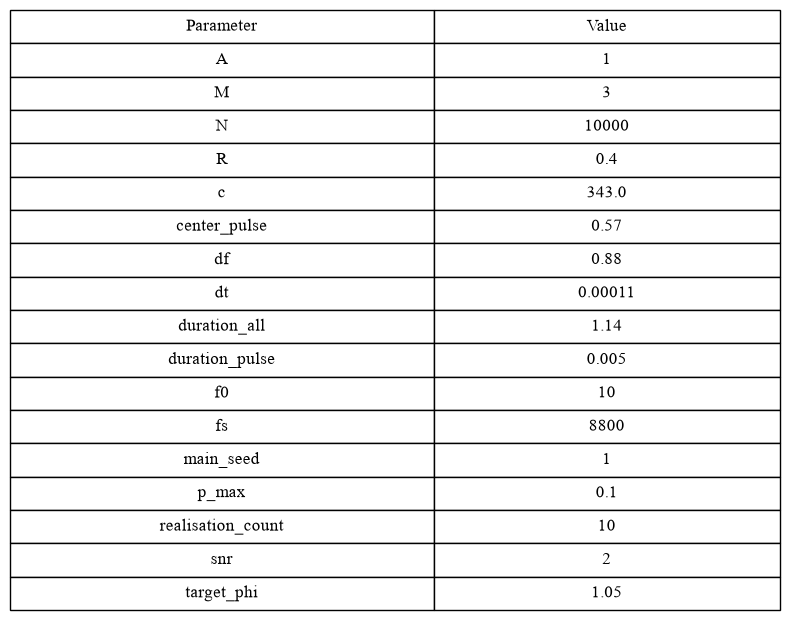

In [ ]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import src.configs.config as config
import src.signals as signals
import src.model as model
import src.configs.comon as comon
import src.experement as experement
import os
import src.plotting as plotting
import src.pseudospectrum as pseudospectrum
config_parametrs = config.init_rng()
path = "attachment/images/notebook"
os.makedirs(path,exist_ok=True)

plotting.create_config_table(config_parametrs)

In [73]:
#sin_signal = signals.get_sin_signal(config_parametrs)
sin_signal = signals.sinus(config_parametrs)
energy_pulse_value = signals.calculate_energy(sin_signal, config_parametrs["time_vector"])


In [74]:
sin_signal = signals.sinus(config_parametrs)


In [75]:
taus = model.tau_array(config_parametrs)
params_vector_copy = config_parametrs.copy()


In [76]:

channel_matrix = model.channel_matrix(config_parametrs, taus, signals.sinus)
W = model.covariation_matrix(channel_matrix, comon.N)
dir_matrix = model.complex_stiring_matrix(config_parametrs)
dir_complex_matrix = model.complex_stiring_matrix(config_parametrs)

In [ ]:
E_bar_true = pseudospectrum.exact_bartlett(W,dir_complex_matrix)
E_bar = pseudospectrum.approx_bartlett(W, dir_matrix)
E_cap = pseudospectrum.approx_capon(W, dir_matrix)
E_cap_true = pseudospectrum.excact_capon(W,dir_complex_matrix)

d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)
d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\collections.py:205: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)
d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\transforms.py:2914: ComplexWarning: Casting complex values to real discards the imaginary part
  vmin, vmax = map(float, [vmin, vmax])


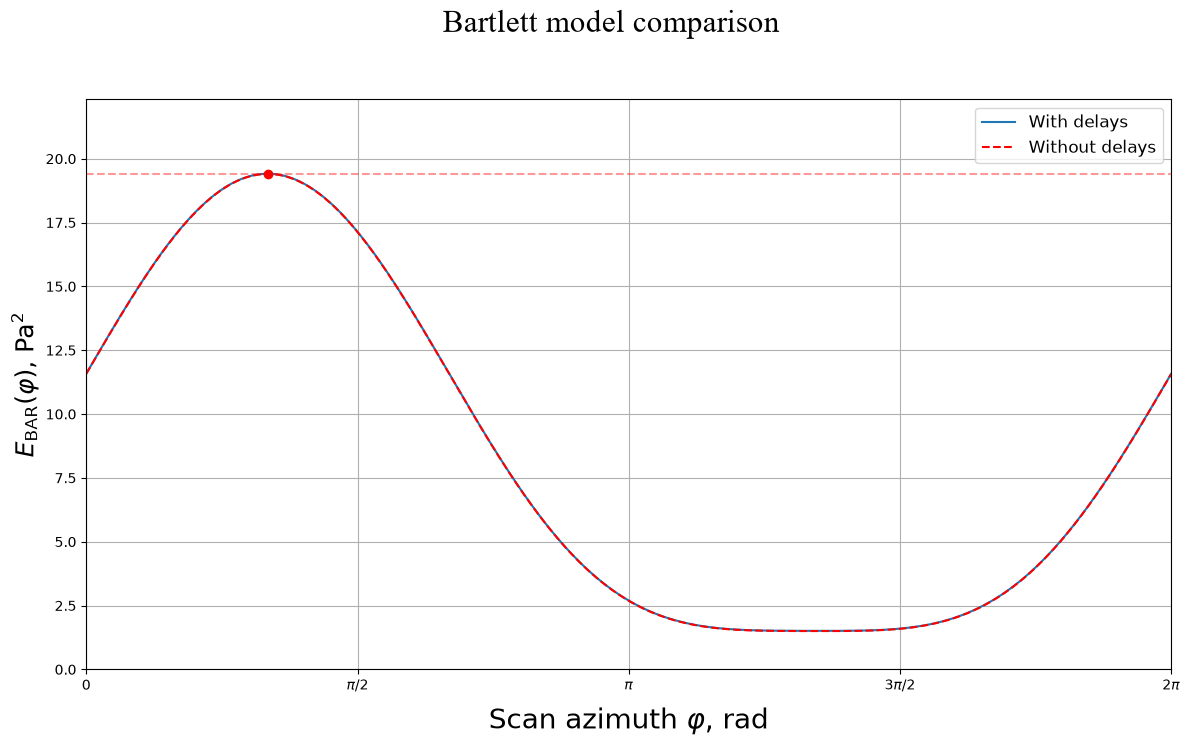

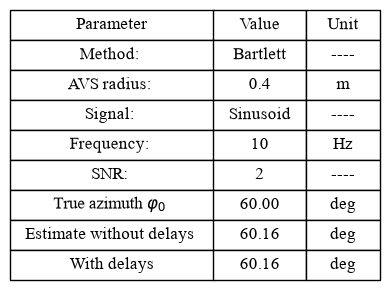

In [ ]:
title_main = "Bartlett model comparison"

snr_ratio = comon.SNR
energy_signal = signals.calculate_energy(sin_signal,config.TIME_VECTOR)
sigma_noise = signals.calculate_noise_level(energy_signal, snr_ratio, comon.DURATION_ALL)
phi_0 = comon.TARGET_PHI
phi_vector = config.PHI_VECTOR
A = comon.A

est_phi_true = experement.estimate_athimut(phi_vector, E_bar_true)
est_phi = experement.estimate_athimut(phi_vector, E_bar)

E_max_true = max(E_bar_true)
E_max = max(E_bar)

snr_text = (
    "∞ ( )" if np.isinf(snr_ratio)
    else f"{snr_ratio:.2f}"
)

fig, ax = plt.subplots(figsize = (14,10))
fig.subplots_adjust(top=0.85, bottom=0.28)

# Функция Бартлетта и отметки углов.
ax.plot(
    phi_vector, E_bar_true,
    label=r"With delays"
)
ax.plot(
    phi_vector, E_bar,
    linestyle = "--",
    color = "red",
    label = "Without delays"
)



ax.scatter(est_phi_true, E_max_true, color="red", zorder=3)
ax.axhline(E_max_true, color="red", linestyle="--", alpha=0.4)

# Названия осей и заголовок
fig.suptitle(
    title_main,
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.set_xlabel(r"Scan azimuth $\varphi$, rad", labelpad=10, fontsize=20)
ax.set_ylabel(r"$E_{\mathrm{BAR}}(\varphi)$, Pa$^2$", fontsize=18)

ax.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
)

ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(0, 1.15 * max(E_max_true, E_max))
ax.legend(loc="upper right", fontsize=12)
ax.grid(True)


plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()
rows = [
    [r"Method: ", "Bartlett", "----"],
    [r"AVS radius: ", f"{comon.RADIUS}", "m"],
    [r"Signal: ", r"Sinusoid", "----"],
    [r"Frequency: ", f"{comon.F_GARMONIC}", "Hz"],
    [r"SNR: ", f"{comon.SNR}", "----"],
    [r"True azimuth $\varphi_{0}$ ", f"{(comon.TARGET_PHI*180)/np.pi:.2f}", "deg"],
    [r"Estimate without delays ", f"{(est_phi*180)/np.pi:.2f}", "deg"],
    [r"With delays", f"{(est_phi_true*180)/np.pi:.2f}", "deg"]]
plotting.create_and_save_table(rows, ["Parameter", "Value", "Unit"], f"attachment/images/notebook/table_{title_main}")


d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)
d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\collections.py:205: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)
d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\transforms.py:2914: ComplexWarning: Casting complex values to real discards the imaginary part
  vmin, vmax = map(float, [vmin, vmax])


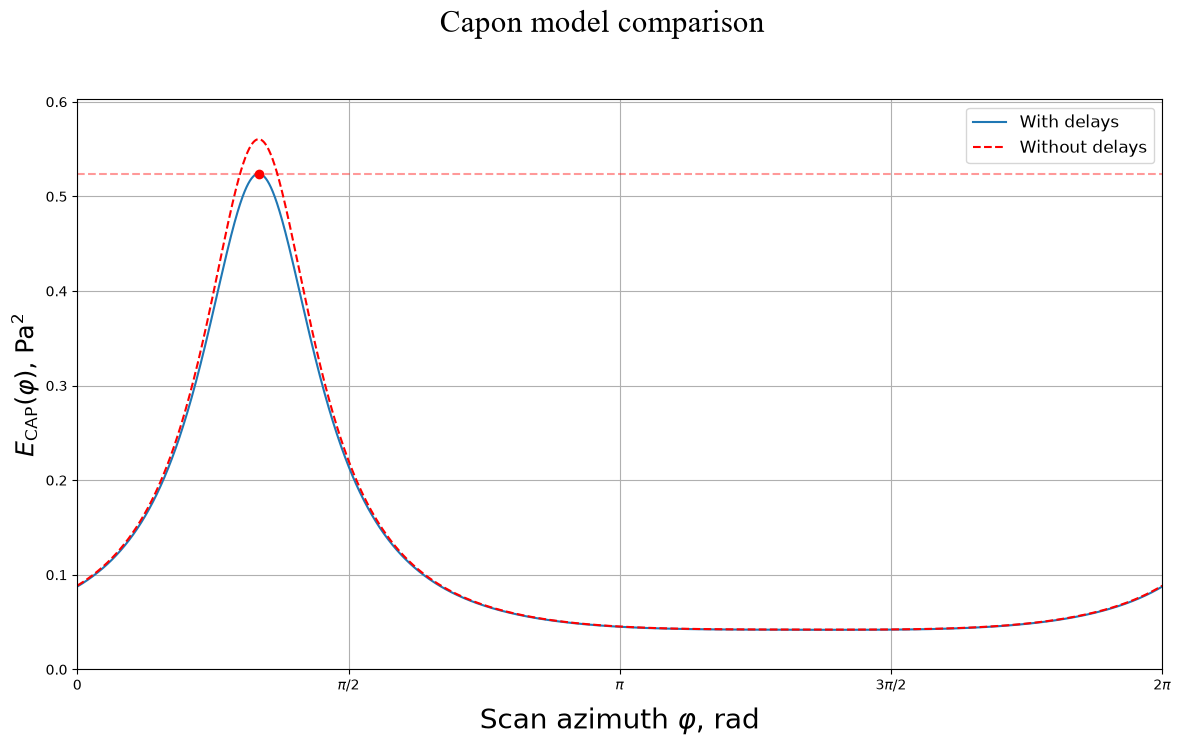

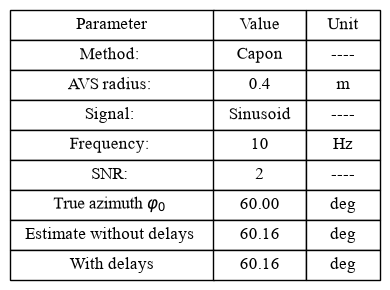

In [ ]:
title_main = "Capon model comparison"

snr_ratio = comon.SNR
energy_signal = signals.calculate_energy(sin_signal,config.TIME_VECTOR)
sigma_noise = signals.calculate_noise_level(energy_signal, snr_ratio, comon.DURATION_ALL)
phi_0 = comon.TARGET_PHI
phi_vector = config.PHI_VECTOR
A = comon.A

est_phi_true = experement.estimate_athimut(phi_vector, E_cap_true)
est_phi = experement.estimate_athimut(phi_vector, E_cap)

E_max_true = max(E_cap_true)
E_max = max(E_cap)

snr_text = (
    "∞ ( )" if np.isinf(snr_ratio)
    else f"{snr_ratio:.2f}"
)

fig, ax = plt.subplots(figsize = (14,10))
fig.subplots_adjust(top=0.85, bottom=0.28)

# Функция Кейпона и отметки углов.
ax.plot(
    phi_vector, E_cap_true,
    label=r"With delays"
)
ax.plot(
    phi_vector, E_cap,
    linestyle = "--",
    color = "red",
    label = "Without delays"
)

ax.scatter(est_phi_true, E_max_true, color="red", zorder=3)
ax.axhline(E_max_true, color="red", linestyle="--", alpha=0.4)

# Названия осей и заголовок
fig.suptitle(
    title_main,
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.set_xlabel(r"Scan azimuth $\varphi$, rad", labelpad=10, fontsize=20)
ax.set_ylabel(r"$E_{\mathrm{CAP}}(\varphi)$, Pa$^2$", fontsize=18)

ax.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
)

ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(0, 1.15*E_max_true)
ax.legend(loc="upper right", fontsize=12)
ax.grid(True)


plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()
rows = [
    [r"Method: ", "Capon", "----"],
    [r"AVS radius: ", f"{comon.RADIUS}", "m"],
    [r"Signal: ", r"Sinusoid", "----"],
    [r"Frequency: ", f"{comon.F_GARMONIC}", "Hz"],
    [r"SNR: ", f"{comon.SNR}", "----"],
    [r"True azimuth $\varphi_{0}$ ", f"{(comon.TARGET_PHI*180)/np.pi:.2f}", "deg"],
    [r"Estimate without delays ", f"{(est_phi*180)/np.pi:.2f}", "deg"],
    [r"With delays", f"{(est_phi_true*180)/np.pi:.2f}", "deg"]]
plotting.create_and_save_table(rows, ["Parameter", "Value", "Unit"], f"attachment/images/notebook/table_{title_main}")
